# 10 — Subject-count ablation

Test whether subject count is the bottleneck for cross-user generalization. Protocol: one day per subject so the variable under test (subject count) is isolated. The internal participants are restricted to day 1 only to match the externals' single-day data.

**Subject sets:**
- 3-subject LOSO: athina, babis, xiomara (each restricted to day 1)
- 4-subject LOSO: + laura
- 5-subject LOSO: + monika

**Models:**
- RF + Set A (the headline classical model from notebook 07)
- TCN (the deep learning comparator from notebook 06), in an optional section

**Expected outcome.** If subject count is the bottleneck (our hypothesis), macro-F1 should trend up with more subjects. If the TCN trend is steeper than the RF trend, that is direct evidence that the TCN's poor performance in notebook 06 was a small-data problem rather than an architecture problem.

**If both trends are flat or going the wrong way:** our hypothesis is wrong, and the report has to be honest about that.

**Comparison reference.** The headline 3-subject LOSO number from notebook 07 used three days of data (0.568). The 3-subject result in this notebook uses one day only, so it is not directly comparable to the headline. The within-this-notebook trend (3, 4, 5) is what matters.

**Outputs.** `reports/results/subject_count_ablation_rf.csv`, `subject_count_ablation_tcn.csv`, and `subject_count_summary.csv`. Plus trajectory figures in `reports/figures/`.

**Runtime.** RF section: about five minutes. TCN section: about thirty minutes per subject count on a reasonable GPU, longer on CPU. Skip the TCN section if you are short on time; the RF trajectory is sufficient on its own for the discussion section.

## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path
from itertools import product

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import f1_score, confusion_matrix

warnings.filterwarnings('ignore')

PROJECT_ROOT = Path('..').resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import features as F

PROCESSED_INT_DIR  = PROJECT_ROOT / 'data' / 'processed'
PROCESSED_EXT_DIR  = PROJECT_ROOT / 'data' / 'processed_external'
INTERIM_INT_DIR    = PROJECT_ROOT / 'data' / 'interim'
INTERIM_EXT_DIR    = PROJECT_ROOT / 'data' / 'interim_external'
FEATURES_DIR       = PROJECT_ROOT / 'reports' / 'features'
RESULTS_DIR        = PROJECT_ROOT / 'reports' / 'results'
FIGURES_DIR        = PROJECT_ROOT / 'reports' / 'figures'

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Load features and restrict to day 1

Merge internal and external feature CSVs, then keep only day 1 sessions for the internals. The externals already have day 1 only. After this filter, every participant contributes the same temporal slice.

In [2]:
int_df = pd.read_csv(PROCESSED_INT_DIR / 'features_common_no_baro.csv')
ext_df = pd.read_csv(PROCESSED_EXT_DIR / 'features_external_no_baro.csv')

print(f'Internal: {len(int_df)} rows, participants={sorted(int_df["participant"].unique())}, '
      f'days={sorted(int_df["day"].unique())}')
print(f'External: {len(ext_df)} rows, participants={sorted(ext_df["participant"].unique())}, '
      f'days={sorted(ext_df["day"].unique())}')

# Use intersection of columns to avoid schema mismatch
common_cols = sorted(set(int_df.columns) & set(ext_df.columns))
missing_in_ext = set(int_df.columns) - set(ext_df.columns)
missing_in_int = set(ext_df.columns) - set(int_df.columns)
if missing_in_ext:
    print(f'  WARNING: columns in internal but not external: {sorted(missing_in_ext)[:10]}')
if missing_in_int:
    print(f'  WARNING: columns in external but not internal: {sorted(missing_in_int)[:10]}')
print(f'  Using {len(common_cols)} common columns')

int_df = int_df[common_cols].copy()
ext_df = ext_df[common_cols].copy()

# Restrict internals to day 1
int_day1 = int_df[int_df['day'] == 'day1'].copy()
print(f'\nInternal day 1 only: {len(int_day1)} rows')
print('Per-participant counts:')
print(int_day1.groupby('participant').size().to_string())

# Merge
merged = pd.concat([int_day1, ext_df], ignore_index=True)
print(f'\nMerged dataset: {len(merged)} rows, {len(merged.columns)} cols')
print('Participants and window counts:')
print(merged.groupby('participant').size().to_string())

Internal: 14513 rows, participants=['athina', 'babis', 'xiomara'], days=['day1', 'day2', 'day3']
External: 5274 rows, participants=['laura', 'maria', 'monika'], days=['day1']
  Using 138 common columns

Internal day 1 only: 4885 rows
Per-participant counts:
participant
athina     1564
babis      1568
xiomara    1753

Merged dataset: 10159 rows, 138 cols
Participants and window counts:
participant
athina     1564
babis      1568
laura      1615
maria      1480
monika     2179
xiomara    1753


## 3. Subject sets and RF + Set A LOSO function

Set A is `time_domain_basic + slope` from the inventory file. RF hyperparameters match notebook 07's selected configuration.

In [3]:
# Set A feature columns
inventory = pd.read_csv(FEATURES_DIR / 'feature_inventory.csv')
set_a_cols = inventory.loc[
    inventory['family'].isin(['time_domain_basic', 'slope']),
    'feature'
].tolist()
set_a_cols = [c for c in set_a_cols if c in merged.columns]
print(f'Set A features available: {len(set_a_cols)}')

# Subject sets to evaluate
SUBJECT_SETS = {
    3: ['athina', 'babis', 'xiomara'],
    4: ['athina', 'babis', 'xiomara', 'laura'],
    5: ['athina', 'babis', 'xiomara', 'laura', 'monika'],
    6: ['athina', 'babis', 'xiomara', 'laura', 'monika', 'maria'],
}

# Check availability
available = set(merged['participant'].unique())
for n, subjects in SUBJECT_SETS.items():
    missing = [s for s in subjects if s not in available]
    if missing:
        print(f'  WARNING: {n}-subject set missing {missing}, will skip')

RF_KWARGS = dict(
    n_estimators=300,
    max_depth=20,
    min_samples_leaf=1,
    class_weight='balanced',
    n_jobs=-1,
    random_state=RANDOM_STATE,
)

def run_rf_loso(merged_df, subjects, feature_cols, rf_kwargs):
    """Run LOSO with RF + Set A on the given subject subset."""
    sub = merged_df[merged_df['participant'].isin(subjects)].copy()
    if sub.empty:
        return None
    X = sub[feature_cols].values
    y = sub['mode_id'].values
    groups = sub['participant'].values

    loso = LeaveOneGroupOut()
    rows = []
    for fold_idx, (tr, te) in enumerate(loso.split(X, y, groups=groups)):
        model = RandomForestClassifier(**rf_kwargs)
        model.fit(X[tr], y[tr])
        y_pred = model.predict(X[te])
        macro_f1 = f1_score(y[te], y_pred, average='macro')
        held_out = groups[te][0]
        rows.append({
            'fold':      fold_idx,
            'held_out':  held_out,
            'n_train':   int(len(tr)),
            'n_test':    int(len(te)),
            'macro_f1':  float(macro_f1),
        })
    return pd.DataFrame(rows)

Set A features available: 80


## 4. Run RF + Set A across all three subject sets

In [4]:
rf_all_results = []
for n_subj, subjects in SUBJECT_SETS.items():
    print(f'\n=== RF + Set A, {n_subj}-subject LOSO ===')
    df_fold = run_rf_loso(merged, subjects, set_a_cols, RF_KWARGS)
    if df_fold is None:
        print('  skipped (no data)')
        continue
    df_fold['n_subjects'] = n_subj
    print(df_fold.to_string(index=False))
    print(f'  Mean macro-F1: {df_fold["macro_f1"].mean():.3f} '
          f'+/- {df_fold["macro_f1"].std():.3f}')
    rf_all_results.append(df_fold)

rf_full = pd.concat(rf_all_results, ignore_index=True)
rf_full.to_csv(RESULTS_DIR / 'subject_count_ablation_rf.csv', index=False)
print(f'\nSaved: {RESULTS_DIR / "subject_count_ablation_rf.csv"}')


=== RF + Set A, 3-subject LOSO ===
 fold held_out  n_train  n_test  macro_f1  n_subjects
    0   athina     3321    1564  0.557096           3
    1    babis     3317    1568  0.527708           3
    2  xiomara     3132    1753  0.665659           3
  Mean macro-F1: 0.583 +/- 0.073

=== RF + Set A, 4-subject LOSO ===
 fold held_out  n_train  n_test  macro_f1  n_subjects
    0   athina     4936    1564  0.459811           4
    1    babis     4932    1568  0.710012           4
    2    laura     4885    1615  0.735960           4
    3  xiomara     4747    1753  0.662357           4
  Mean macro-F1: 0.642 +/- 0.125

=== RF + Set A, 5-subject LOSO ===
 fold held_out  n_train  n_test  macro_f1  n_subjects
    0   athina     7115    1564  0.430441           5
    1    babis     7111    1568  0.730027           5
    2    laura     7064    1615  0.776501           5
    3   monika     6500    2179  0.676698           5
    4  xiomara     6926    1753  0.659551           5
  Mean macro-F1:

## 5. RF trajectory and per-fold breakdown

In [5]:
rf_summary = rf_full.groupby('n_subjects').agg(
    mean_f1=('macro_f1', 'mean'),
    std_f1=('macro_f1', 'std'),
    min_f1=('macro_f1', 'min'),
    max_f1=('macro_f1', 'max'),
    n_folds=('macro_f1', 'count'),
).reset_index()
rf_summary['mean_f1'] = rf_summary['mean_f1'].round(3)
rf_summary['std_f1']  = rf_summary['std_f1'].round(3)
print('RF + Set A trajectory:')
print(rf_summary.to_string(index=False))

# Per-fold breakdown for diagnostic
print('\nPer-fold detail:')
for n_subj in sorted(rf_full['n_subjects'].unique()):
    sub = rf_full[rf_full['n_subjects'] == n_subj]
    folds = ', '.join(f"{r['held_out']}={r['macro_f1']:.3f}" for _, r in sub.iterrows())
    print(f'  {n_subj}-subject: {folds}')

RF + Set A trajectory:
 n_subjects  mean_f1  std_f1   min_f1   max_f1  n_folds
          3    0.583   0.073 0.527708 0.665659        3
          4    0.642   0.125 0.459811 0.735960        4
          5    0.655   0.134 0.430441 0.776501        5
          6    0.573   0.157 0.371910 0.749416        6

Per-fold detail:
  3-subject: athina=0.557, babis=0.528, xiomara=0.666
  4-subject: athina=0.460, babis=0.710, laura=0.736, xiomara=0.662
  5-subject: athina=0.430, babis=0.730, laura=0.777, monika=0.677, xiomara=0.660
  6-subject: athina=0.411, babis=0.708, laura=0.749, maria=0.372, monika=0.544, xiomara=0.655


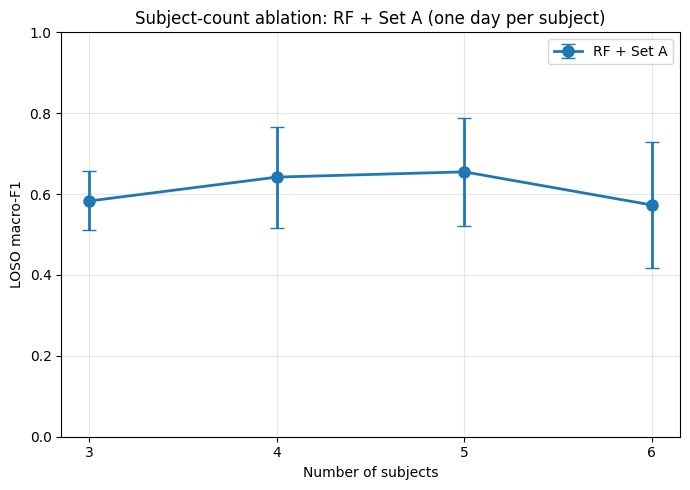

Saved: C:\Projects\this project-transport-mode\reports\figures\subject_count_trajectory_rf.png


In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(
    rf_summary['n_subjects'], rf_summary['mean_f1'],
    yerr=rf_summary['std_f1'], marker='o', capsize=5,
    color='C0', linewidth=2, markersize=8, label='RF + Set A',
)
ax.set_xlabel('Number of subjects')
ax.set_ylabel('LOSO macro-F1')
ax.set_title('Subject-count ablation: RF + Set A (one day per subject)')
ax.set_xticks([3, 4, 5, 6])
ax.set_ylim(0, 1)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'subject_count_trajectory_rf.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()
print(f'Saved: {FIGURES_DIR / "subject_count_trajectory_rf.png"}')

## 6. TCN subject-count ablation (optional)

This section is expensive. About thirty minutes per subject count on a reasonable GPU, longer on CPU. If you skip it, jump to the combined summary in section 11; the RF trajectory alone is sufficient for the discussion section.

**Architecture.** Five-block TCN with dilations [1, 2, 4, 8, 16], channel widths [32, 64, 128, 128, 128], kernel size 3, dropout 0.2. Receptive field is about 125 samples (2.5 seconds at 50 Hz). This matches the `tcn_large` configuration used in notebook 06.

**Caveat.** This is a clean reference implementation rather than an exact replica of notebook 06's code. The within-this-notebook trajectory across subject counts is what matters for the ablation; comparing the 3-subject absolute number here against notebook 06's 3-subject number is not meaningful because the data scope differs (one day here, three days there).

**Prerequisite.** `torch` must be installed. The notebook will skip this section gracefully if torch is unavailable.

In [7]:
TCN_AVAILABLE = False
try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as Fnn
    import torch.optim as optim
    from torch.utils.data import DataLoader, TensorDataset
    DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
    TCN_AVAILABLE = True
    print(f'torch available, device = {DEVICE}')
except ImportError:
    print('torch not installed. TCN section will be skipped.')
    DEVICE = 'cpu'

torch available, device = cuda


## 7. Build raw windows from interim CSVs (day 1 only)

Walk through the relevant interim files and extract 5-second windows at 50 Hz with 50 percent overlap. Channel set is auto-detected: if all sessions have `acc_x/y/z` it is nine channels, otherwise six. Bad samples are filtered out the same way as in feature extraction.

In [8]:
if TCN_AVAILABLE:
    SAMPLING_RATE = 50
    WINDOW_SAMPLES = SAMPLING_RATE * 5    # 250
    STRIDE_SAMPLES = WINDOW_SAMPLES // 2  # 125 (50% overlap)

    BASE_CHANNELS = ['lin_ax', 'lin_ay', 'lin_az', 'gx', 'gy', 'gz']
    ACC_CHANNELS  = ['acc_x', 'acc_y', 'acc_z']

    def discover_day1_sessions():
        """Find day-1 interim files for all participants (internal + external)."""
        files = []
        for d in (INTERIM_INT_DIR, INTERIM_EXT_DIR):
            if not d.exists():
                continue
            for p in d.glob('*_day1.csv'):
                name = p.stem  # e.g. 'babis_walking_day1'
                parts = name.split('_')
                if len(parts) < 3 or parts[1] not in F.MODES:
                    continue
                files.append({
                    'session_id':  name,
                    'participant': parts[0],
                    'mode':        parts[1],
                    'mode_id':     F.MODE_TO_ID[parts[1]],
                    'day':         'day1',
                    'path':        p,
                })
        return files

    sessions = discover_day1_sessions()
    print(f'Day-1 sessions discovered: {len(sessions)}')

    # Auto-detect channel set
    channels = list(BASE_CHANNELS)
    sample_df = pd.read_csv(sessions[0]['path'], nrows=5)
    if all(c in sample_df.columns for c in ACC_CHANNELS):
        # Verify all sessions have acc
        all_have_acc = all(
            all(c in pd.read_csv(s['path'], nrows=2).columns for c in ACC_CHANNELS)
            for s in sessions
        )
        if all_have_acc:
            channels += ACC_CHANNELS
            print(f'All sessions have raw accelerometer; using 9 channels')
        else:
            print(f'Not all sessions have raw accelerometer; using 6 channels')
    else:
        print(f'Reference session lacks raw accelerometer; using 6 channels')
    print(f'Channels: {channels}')

    def build_windows(session_list):
        X_list, y_list, g_list = [], [], []
        for s in session_list:
            df = pd.read_csv(s['path']).reset_index(drop=True)
            has_bad = 'bad_sample' in df.columns
            if not all(c in df.columns for c in channels):
                continue  # missing channels, skip session
            signal = df[channels].values  # (T, C)
            for start in range(0, len(signal) - WINDOW_SAMPLES + 1, STRIDE_SAMPLES):
                end = start + WINDOW_SAMPLES
                if has_bad and bool(df['bad_sample'].iloc[start:end].any()):
                    continue
                X_list.append(signal[start:end].T)  # (C, T)
                y_list.append(s['mode_id'])
                g_list.append(s['participant'])
        return (np.array(X_list, dtype=np.float32),
                np.array(y_list, dtype=np.int64),
                np.array(g_list))

    X_all, y_all, g_all = build_windows(sessions)
    print(f'\nAll windows: {X_all.shape}, labels {y_all.shape}, groups {g_all.shape}')
    print(f'Per-participant counts:')
    for p in sorted(set(g_all)):
        print(f'  {p:10s}: {int((g_all == p).sum())} windows')

Day-1 sessions discovered: 36
Reference session lacks raw accelerometer; using 6 channels
Channels: ['lin_ax', 'lin_ay', 'lin_az', 'gx', 'gy', 'gz']

All windows: (10159, 6, 250), labels (10159,), groups (10159,)
Per-participant counts:
  athina    : 1564 windows
  babis     : 1568 windows
  laura     : 1615 windows
  maria     : 1480 windows
  monika    : 2179 windows
  xiomara   : 1753 windows


## 8. TCN architecture

Standard residual TCN (Bai et al. 2018) with causal dilated convolutions, batch norm, dropout, global average pooling, linear classification head.

In [9]:
if TCN_AVAILABLE:
    class Chomp1d(nn.Module):
        """Remove the right-side padding so the convolution is causal."""
        def __init__(self, chomp):
            super().__init__()
            self.chomp = chomp
        def forward(self, x):
            return x[:, :, :-self.chomp].contiguous() if self.chomp > 0 else x

    class TemporalBlock(nn.Module):
        def __init__(self, c_in, c_out, kernel_size, dilation, dropout):
            super().__init__()
            pad = (kernel_size - 1) * dilation
            self.net = nn.Sequential(
                nn.Conv1d(c_in, c_out, kernel_size, padding=pad, dilation=dilation),
                Chomp1d(pad),
                nn.BatchNorm1d(c_out),
                nn.ReLU(),
                nn.Dropout(dropout),
                nn.Conv1d(c_out, c_out, kernel_size, padding=pad, dilation=dilation),
                Chomp1d(pad),
                nn.BatchNorm1d(c_out),
                nn.ReLU(),
                nn.Dropout(dropout),
            )
            self.downsample = nn.Conv1d(c_in, c_out, 1) if c_in != c_out else None
        def forward(self, x):
            out = self.net(x)
            res = x if self.downsample is None else self.downsample(x)
            return Fnn.relu(out + res)

    class TCN(nn.Module):
        def __init__(self, in_channels, num_classes=6,
                     widths=(32, 64, 128, 128, 128),
                     dilations=(1, 2, 4, 8, 16),
                     kernel_size=3, dropout=0.2):
            super().__init__()
            blocks = []
            prev = in_channels
            for c, d in zip(widths, dilations):
                blocks.append(TemporalBlock(prev, c, kernel_size, d, dropout))
                prev = c
            self.network = nn.Sequential(*blocks)
            self.head = nn.Linear(prev, num_classes)
        def forward(self, x):
            out = self.network(x)        # (B, C, T)
            out = out.mean(dim=-1)       # GAP over time
            return self.head(out)

    # Quick smoke test
    m = TCN(in_channels=len(channels))
    n_params = sum(p.numel() for p in m.parameters())
    print(f'TCN (tcn_large) parameters: {n_params:,}')
    out = m(torch.randn(2, len(channels), WINDOW_SAMPLES))
    print(f'Forward shape: {out.shape}')

TCN (tcn_large) parameters: 306,726
Forward shape: torch.Size([2, 6])


## 9. TCN training and LOSO function

Train for fixed epochs with Adam, cross-entropy loss, per-channel standardization on the training fold only.

In [10]:
if TCN_AVAILABLE:
    def train_and_eval_tcn(X_tr, y_tr, X_te, y_te,
                            n_epochs=30, batch_size=64, lr=1e-3, device=DEVICE):
        # Per-channel standardization using train stats only
        mean = X_tr.mean(axis=(0, 2), keepdims=True)
        std  = X_tr.std(axis=(0, 2), keepdims=True) + 1e-6
        X_tr_n = (X_tr - mean) / std
        X_te_n = (X_te - mean) / std

        train_ds = TensorDataset(
            torch.tensor(X_tr_n, dtype=torch.float32),
            torch.tensor(y_tr, dtype=torch.long),
        )
        train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True)

        model = TCN(in_channels=X_tr.shape[1]).to(device)
        opt = optim.Adam(model.parameters(), lr=lr)
        loss_fn = nn.CrossEntropyLoss()

        model.train()
        for epoch in range(n_epochs):
            for xb, yb in train_loader:
                xb, yb = xb.to(device), yb.to(device)
                opt.zero_grad()
                loss = loss_fn(model(xb), yb)
                loss.backward()
                opt.step()

        model.eval()
        with torch.no_grad():
            X_te_t = torch.tensor(X_te_n, dtype=torch.float32).to(device)
            y_pred = model(X_te_t).argmax(dim=1).cpu().numpy()
        return y_pred

    def run_tcn_loso(X, y, g, subjects, n_epochs=30):
        mask = np.isin(g, subjects)
        Xs, ys, gs = X[mask], y[mask], g[mask]
        if len(Xs) == 0:
            return None
        loso = LeaveOneGroupOut()
        rows = []
        for fold_idx, (tr, te) in enumerate(loso.split(Xs, ys, groups=gs)):
            torch.manual_seed(RANDOM_STATE + fold_idx)
            np.random.seed(RANDOM_STATE + fold_idx)
            y_pred = train_and_eval_tcn(
                Xs[tr], ys[tr], Xs[te], ys[te], n_epochs=n_epochs
            )
            macro_f1 = f1_score(ys[te], y_pred, average='macro')
            held_out = gs[te][0]
            rows.append({
                'fold':      fold_idx,
                'held_out':  held_out,
                'n_train':   int(len(tr)),
                'n_test':    int(len(te)),
                'macro_f1':  float(macro_f1),
            })
            print(f'    fold {fold_idx} ({held_out}): macro-F1 = {macro_f1:.3f}')
        return pd.DataFrame(rows)

## 10. Run TCN across all three subject sets

This is the expensive step. Plan for 30 to 60 minutes depending on hardware. If you need to stop early, the partial results are still saved per subject count.

In [11]:
if TCN_AVAILABLE:
    tcn_all_results = []
    for n_subj, subjects in SUBJECT_SETS.items():
        # Skip if any subject not available in raw windows
        available_g = set(g_all.tolist())
        missing = [s for s in subjects if s not in available_g]
        if missing:
            print(f'\n=== TCN {n_subj}-subject: skipped (missing {missing}) ===')
            continue
        print(f'\n=== TCN tcn_large, {n_subj}-subject LOSO ===')
        df_fold = run_tcn_loso(X_all, y_all, g_all, subjects, n_epochs=30)
        if df_fold is None:
            continue
        df_fold['n_subjects'] = n_subj
        tcn_all_results.append(df_fold)
        # Save incrementally so partial progress is recoverable
        pd.concat(tcn_all_results, ignore_index=True).to_csv(
            RESULTS_DIR / 'subject_count_ablation_tcn.csv', index=False
        )
        print(f'  Mean macro-F1: {df_fold["macro_f1"].mean():.3f} '
              f'+/- {df_fold["macro_f1"].std():.3f}')

    if tcn_all_results:
        tcn_full = pd.concat(tcn_all_results, ignore_index=True)
        print(f'\nSaved: {RESULTS_DIR / "subject_count_ablation_tcn.csv"}')
    else:
        tcn_full = None
        print('No TCN results produced')
else:
    tcn_full = None


=== TCN tcn_large, 3-subject LOSO ===
    fold 0 (athina): macro-F1 = 0.392
    fold 1 (babis): macro-F1 = 0.390
    fold 2 (xiomara): macro-F1 = 0.558
  Mean macro-F1: 0.447 +/- 0.096

=== TCN tcn_large, 4-subject LOSO ===
    fold 0 (athina): macro-F1 = 0.275
    fold 1 (babis): macro-F1 = 0.358
    fold 2 (laura): macro-F1 = 0.274
    fold 3 (xiomara): macro-F1 = 0.273
  Mean macro-F1: 0.295 +/- 0.042

=== TCN tcn_large, 5-subject LOSO ===
    fold 0 (athina): macro-F1 = 0.117
    fold 1 (babis): macro-F1 = 0.404
    fold 2 (laura): macro-F1 = 0.326
    fold 3 (monika): macro-F1 = 0.346
    fold 4 (xiomara): macro-F1 = 0.383
  Mean macro-F1: 0.315 +/- 0.115

=== TCN tcn_large, 6-subject LOSO ===
    fold 0 (athina): macro-F1 = 0.221
    fold 1 (babis): macro-F1 = 0.466
    fold 2 (laura): macro-F1 = 0.474
    fold 3 (maria): macro-F1 = 0.220
    fold 4 (monika): macro-F1 = 0.395
    fold 5 (xiomara): macro-F1 = 0.261
  Mean macro-F1: 0.339 +/- 0.120

Saved: C:\Projects\this project

## 11. Combined summary

Headline table comparing RF and TCN trajectories across subject counts. This is the report-ready output.

In [12]:
summary_rows = []
for n_subj in sorted(SUBJECT_SETS.keys()):
    row = {'n_subjects': n_subj}
    rf_sub = rf_full[rf_full['n_subjects'] == n_subj]
    if len(rf_sub) > 0:
        row['rf_mean'] = round(float(rf_sub['macro_f1'].mean()), 3)
        row['rf_std']  = round(float(rf_sub['macro_f1'].std()), 3)
        row['rf_folds'] = int(len(rf_sub))
    if tcn_full is not None:
        tcn_sub = tcn_full[tcn_full['n_subjects'] == n_subj]
        if len(tcn_sub) > 0:
            row['tcn_mean'] = round(float(tcn_sub['macro_f1'].mean()), 3)
            row['tcn_std']  = round(float(tcn_sub['macro_f1'].std()), 3)
            row['tcn_folds'] = int(len(tcn_sub))
    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)
summary_df.to_csv(RESULTS_DIR / 'subject_count_summary.csv', index=False)

print('=' * 60)
print('SUBJECT-COUNT ABLATION SUMMARY (one day per subject)')
print('=' * 60)
print(summary_df.to_string(index=False))
print('=' * 60)

# Trend assessment
if 'rf_mean' in summary_df.columns and summary_df['rf_mean'].notna().sum() >= 2:
    rf_delta = summary_df['rf_mean'].max() - summary_df['rf_mean'].min()
    print(f'\nRF + Set A trajectory range: {rf_delta:+.3f}')
if 'tcn_mean' in summary_df.columns and summary_df['tcn_mean'].notna().sum() >= 2:
    tcn_delta = summary_df['tcn_mean'].max() - summary_df['tcn_mean'].min()
    print(f'TCN trajectory range:         {tcn_delta:+.3f}')

SUBJECT-COUNT ABLATION SUMMARY (one day per subject)
 n_subjects  rf_mean  rf_std  rf_folds  tcn_mean  tcn_std  tcn_folds
          3    0.583   0.073         3     0.447    0.096          3
          4    0.642   0.125         4     0.295    0.042          4
          5    0.655   0.134         5     0.315    0.115          5
          6    0.573   0.157         6     0.339    0.120          6

RF + Set A trajectory range: +0.082
TCN trajectory range:         +0.152


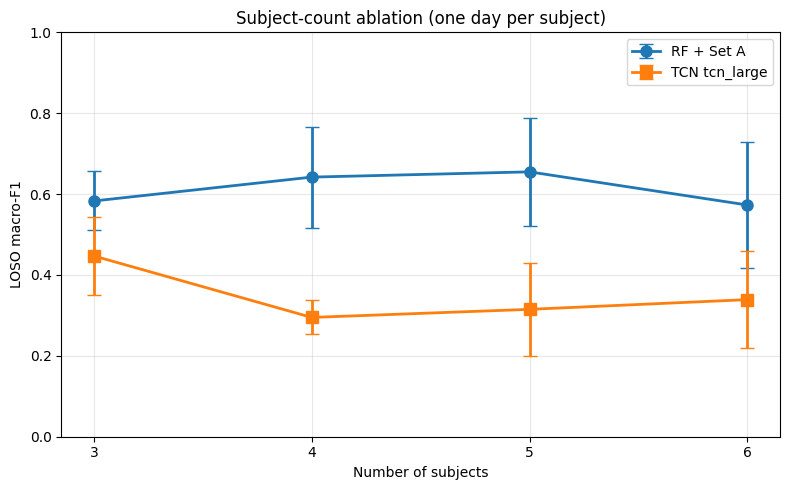

Saved: C:\Projects\this project-transport-mode\reports\figures\subject_count_trajectory_combined.png


In [13]:
# Combined trajectory plot
if 'tcn_mean' in summary_df.columns and summary_df['tcn_mean'].notna().sum() > 0:
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.errorbar(
        summary_df['n_subjects'], summary_df['rf_mean'],
        yerr=summary_df['rf_std'], marker='o', capsize=5,
        color='C0', linewidth=2, markersize=8, label='RF + Set A',
    )
    valid = summary_df.dropna(subset=['tcn_mean'])
    ax.errorbar(
        valid['n_subjects'], valid['tcn_mean'],
        yerr=valid['tcn_std'], marker='s', capsize=5,
        color='C1', linewidth=2, markersize=8, label='TCN tcn_large',
    )
    ax.set_xlabel('Number of subjects')
    ax.set_ylabel('LOSO macro-F1')
    ax.set_title('Subject-count ablation (one day per subject)')
    ax.set_xticks([3, 4, 5, 6])
    ax.set_ylim(0, 1)
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.savefig(FIGURES_DIR / 'subject_count_trajectory_combined.png',
                dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
    print(f'Saved: {FIGURES_DIR / "subject_count_trajectory_combined.png"}')

## 12. Summary and reading order for the discussion

Artifacts produced:
- `reports/results/subject_count_ablation_rf.csv`: per-fold RF results.
- `reports/results/subject_count_ablation_tcn.csv`: per-fold TCN results (if torch was available).
- `reports/results/subject_count_summary.csv`: the headline trajectory table.
- `reports/figures/subject_count_trajectory_rf.png`: RF trajectory plot.
- `reports/figures/subject_count_trajectory_combined.png`: RF + TCN trajectory plot (if TCN ran).

How to read the result for the discussion section:

1. **If both trajectories trend up.** Subject count is the bottleneck. The TCN's three-day collapse in notebook 06 was a small-data problem, not an architecture problem. The report can claim that hand-crafted features generalize better in low-subject regimes specifically, with deep learning catching up at larger N.

2. **If only the RF trends up.** Subject count helps the classical model but the TCN remains stuck at chance-level performance even with more subjects. The TCN's failure mode is structural for this dataset, not just a sample size problem.

3. **If neither trends up.** Our hypothesis was wrong. Adding subjects with one day each does not improve cross-user generalization. The ceiling we hit at 0.568 reflects something deeper than subject count, possibly device diversity (we always have a Samsung A55 in the held-out set when Athina is held out, and so on). The report has to be honest about this.

4. **If only the TCN trends up.** Surprising. Would suggest the TCN was specifically subject-count starved while the RF was already saturated. This is the least likely outcome given the notebook 06 evidence, but worth checking the numbers if it appears.